# Malawi Resource Allocation

This notebook processes Malawi IHS5 (Fifth Integrated Household Survey) 2019/20 data into a household-level dataset for predicting consumption, following the same preprocessing strategy as the Ethiopia LSMS notebook.

**Pipeline:**
1. Load and clean survey data (consumption, assets, housing, demographics, education)
2. Merge into a single household-level dataset
3. Encode features: binary to 0/1, winsorize and scale continuous variables, group rare categories and one hot encode

**Data source:** The survey data can be downloaded from the LSMS program [here](https://microdata.worldbank.org/index.php/catalog/3818).

**Output:** `survey2019.csv`, the processed dataset

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LassoCV

In [2]:
import os
from pathlib import Path

# Data lives outside the repo; override with the MWI_DATA_DIR env var
DATA_DIR = Path(os.environ.get("MWI_DATA_DIR", "~/Downloads/MWI_2019_IHS-V_v06_M_CSV")).expanduser()
assert DATA_DIR.exists(), f"Data folder not found: {DATA_DIR}"

csv_files = sorted(DATA_DIR.glob("*.csv"))
print(f"{len(csv_files)} CSV files in {DATA_DIR}")

108 CSV files in /Users/prisha/Downloads/MWI_2019_IHS-V_v06_M_CSV


## Preprocessing

### Consumption data

In [3]:
# Read consumption aggregate, get HHID + annual real household consumption
# rexpagg is already a household total (spatially and temporally deflated), so no per capita -> total step is needed
cons = pd.read_csv(DATA_DIR / 'ihs5_consumption_aggregate.csv')
cons = cons[['case_id', 'rexpagg']]
cons.columns = ['hhid', 'Consumption']

# Drop any households with missing ID or missing consumption
cons = cons.dropna(how='any')

# Convert Malawi Kwacha per year to USD PPP per year
# World Bank private consumption PPP conversion factor (PA.NUS.PRVT.PP) -- verify the 2019 value before using results
ppp_factor = 306.03
cons['Consumption'] = cons['Consumption']/ppp_factor
print('Households with consumption data: %i' % len(cons))

Households with consumption data: 11434


### Asset data

In [4]:
# Get asset data from durable goods module (hh_l01 = owns item, hh_l02 = item, hh_l03 = number owned)
assets = pd.read_csv(DATA_DIR / 'HH_MOD_L.csv')
assets = assets[['case_id', 'hh_l01', 'hh_l02', 'hh_l03']]
assets.columns = ['hhid', 'owns', 'item', 'count']

# Households that don't own an item have no count; one owner is missing a count, assume they own one
assets.loc[assets['owns'] == 'No', 'count'] = 0
assets['count'] = assets['count'].fillna(1)

# Drop households missing ID and duplicate records
assets = assets.dropna(subset=['hhid'])
assets = assets.drop_duplicates(subset=['hhid', 'item'])

# Pivot to per-household dataset, item names become column names
assets = assets.pivot(index='hhid', columns='item', values='count').fillna(0)
assets.columns.name = None
assets = assets.reset_index()

# Mobile phones aren't in the durable goods module; number of working phones is asked in the housing module (hh_f34)
phones = pd.read_csv(DATA_DIR / 'HH_MOD_F.csv', usecols=['case_id', 'hh_f34'])
phones.columns = ['hhid', 'Mobile phone']
assets = assets.merge(phones, on='hhid', how='left')
assets['Mobile phone'] = assets['Mobile phone'].fillna(0)
print('Households with asset data: %i' % len(assets))

Households with asset data: 11434


### Housing data

In [5]:
# Get housing data from housing module
housing = pd.read_csv(DATA_DIR / 'HH_MOD_F.csv', low_memory=False)
housing = housing[['case_id', 'hh_f01', 'hh_f06', 'hh_f07', 'hh_f08', 'hh_f09', 'hh_f10', 'hh_f11', 'hh_f12',
                   'hh_f19', 'hh_f36', 'hh_f41', 'hh_f43']]
colnames = ['hhid', 'Ownership status', 'Dwelling type', 'Walls', 'Roof', 'Floor', 'Rooms', 'Lighting fuel',
            'Cooking fuel', 'Electricity', 'Water source', 'Toilet', 'Garbage']
housing.columns = colnames

# Drop households missing IDs, no other column has missingness
housing = housing.dropna()

print('Households with housing data: %i' % len(housing))

Households with housing data: 11434


### Demographic data

In [6]:
# Get demographic data from household roster module
demographics = pd.read_csv(DATA_DIR / 'HH_MOD_B.csv', low_memory=False)
demographics = demographics[['case_id', 'hh_b04', 'hh_b03', 'hh_b05a', 'hh_b24']]
demographics.columns = ['hhid', 'relationship', 'gender', 'age', 'married']

# Marital status is only asked of members 12+, add missing category
demographics['married'] = demographics['married'].fillna('MISSING')

# Drop any rows missing ID
demographics = demographics.dropna(subset=['hhid'])

# Create dataframe of household head data (every household has exactly one head)
hhh = demographics[demographics['relationship'] == 'HEAD'].copy()
hhh = hhh[['hhid', 'gender', 'age', 'married']]
hhh.columns = ['hhid', 'HHH gender', 'HHH age', 'HHH married']

# Create dataframe with number of children in household
children = demographics[demographics['age'] < 5].copy()
children = children[['hhid', 'gender']].groupby('hhid', as_index=False).agg('count')\
    .rename({'gender':'Children'}, axis=1)

# Create dataframe with other misc demographic data -- region, urban/rural, number of members
geo = pd.read_csv(DATA_DIR / 'ihs5_consumption_aggregate.csv')
geo = geo[['case_id', 'region', 'urban', 'hhsize']]
geo.columns = ['hhid', 'region', 'urban', 'hh_size']

# Merge all demographic data together
demographics = geo.merge(hhh, on='hhid', how='left').merge(children, on='hhid', how='left')
demographics['Children'] = demographics['Children'].fillna(0)
demographics = demographics.dropna()
print('Households with demographic data: %i' % len(demographics))

Households with demographic data: 11434


### Education data

In [7]:
# Get IDs for just household heads
hhh = pd.read_csv(DATA_DIR / 'HH_MOD_B.csv', low_memory=False)
hhh = hhh[['case_id', 'PID', 'hh_b04']]
hhh.columns = ['hhid', 'pid', 'relationship']
hhh = hhh[hhh['relationship'] == 'HEAD'][['hhid', 'pid']]

# Read education data from education module
# hh_c05_1 / hh_c05_3 = can read in Chichewa / English, hh_c06 = ever attended school, hh_c09 = highest qualification
education = pd.read_csv(DATA_DIR / 'HH_MOD_C.csv', low_memory=False)
education = education[['case_id', 'PID', 'hh_c05_1', 'hh_c05_3', 'hh_c06', 'hh_c09']]
education.columns = ['hhid', 'pid', 'literate_chichewa', 'literate_english', 'school', 'level_school']

# Merge education data to IDs to get education data for just household heads
education = education.merge(hhh, on=['hhid', 'pid'], how='inner').drop('pid', axis=1)

# Recode literacy (literate in either language) and education variables
education['literate'] = ((education['literate_chichewa'] == 'YES') | (education['literate_english'] == 'YES')).astype(int)
education['level_school'] = education.apply(lambda row: 'NEVER ATTENDED' if row['school'] == 'NO' else
                                            row['level_school'], axis=1)
education['level_school'] = education['level_school'].fillna('NEVER ATTENDED')
education = education[['hhid', 'literate', 'level_school']]

print('Households with education data: %i' % len(education))

Households with education data: 11434


### Merge all data together

In [8]:
# Combine together all dataframes (HH need to have consumption data, can have other data missing)
df = cons.merge(demographics, on='hhid', how='left').merge(housing, on='hhid', how='left')\
    .merge(assets, on='hhid', how='left').merge(education, on='hhid', how='left')\
    .dropna()\
    .drop_duplicates(subset=['hhid'])

# Get outcome and feature variables
outcome = 'Consumption'
x_vars = [c for c in df.columns if c not in ['hhid', outcome]]

# Define type for each feature variable by name
asset_vars = [c for c in assets.columns if c != 'hhid']
x_var_types = {'region': 'cat', 'urban': 'bin', 'hh_size': 'int', 'HHH gender': 'bin', 'HHH age': 'int',
               'HHH married': 'cat', 'Children': 'int', 'Ownership status': 'cat', 'Dwelling type': 'cat',
               'Walls': 'cat', 'Roof': 'cat', 'Floor': 'cat', 'Rooms': 'int', 'Lighting fuel': 'cat',
               'Cooking fuel': 'cat', 'Electricity': 'bin', 'Water source': 'cat', 'Toilet': 'cat',
               'Garbage': 'cat', 'literate': 'bin', 'level_school': 'cat'}
x_var_types.update({a: 'int' for a in asset_vars})

# Map text-coded binary variables to 0 and 1 (urban is coded 1 = urban, 2 = rural)
binary_maps = {'urban': {1: 1, 2: 0}, 'HHH gender': {'MALE': 0, 'FEMALE': 1}, 'Electricity': {'NO': 0, 'YES': 1}}

for var in x_vars:

    # Check binary variables for having exactly 2 values, and convert values to 0 and 1
    if x_var_types[var] == 'bin':
        if len(df[var].unique()) != 2:
            print('Error: Unique values in column ' + var + ' not equal to 2')
        if var in binary_maps:
            df[var] = df[var].map(binary_maps[var])

    # Winsorize then scale continuous variables, and drop any that have 100% missingness or are constant
    elif x_var_types[var] == 'int':
        cutoff = np.percentile(df[var], 99)
        df[var] = df[var].apply(lambda x: cutoff if x > cutoff else x)
        if df[var].max() == df[var].min():
            df = df.drop(var, axis=1)
            continue
        df[var] = (df[var] - df[var].min())/(df[var].max() - df[var].min())
        if df[var].isnull().mean() == 1:
            df = df.drop(var, axis=1)

# Combine any categories in categorical variables with <1% of observations into an "Other" category
# and one hot encode
cat_vars = [var for var in x_vars if x_var_types[var] == 'cat']
for cat_var in cat_vars:
    shares = df[cat_var].value_counts(normalize=True)
    to_remove = shares[shares < 0.01].index
    df[cat_var] = df[cat_var].apply(lambda x: 'Other' if x in to_remove else x)
df = pd.get_dummies(df, columns=cat_vars, drop_first=True, dtype=int)

df.to_csv('survey2019.csv', index=False)
print('Households in final dataset: %i' % len(df))

Households in final dataset: 11434


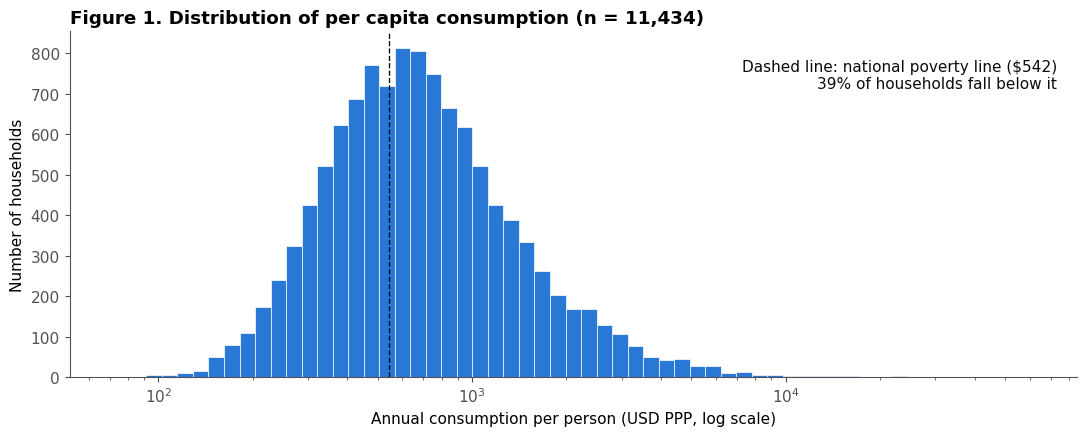

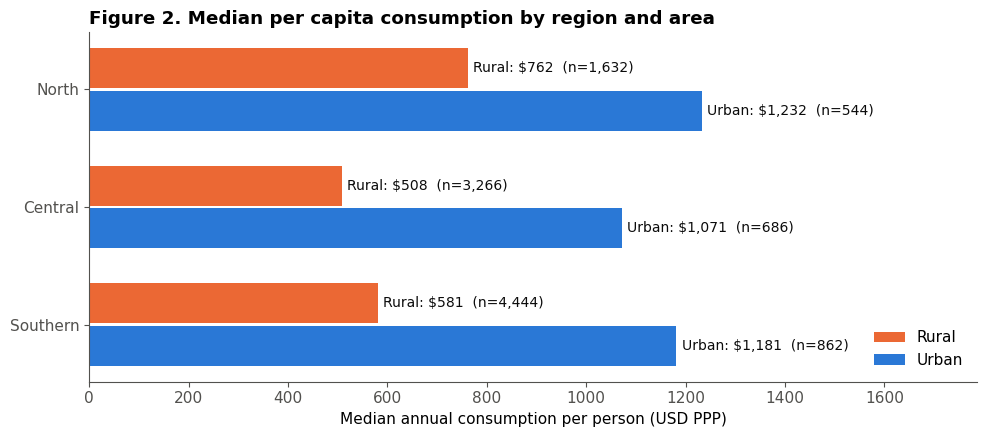

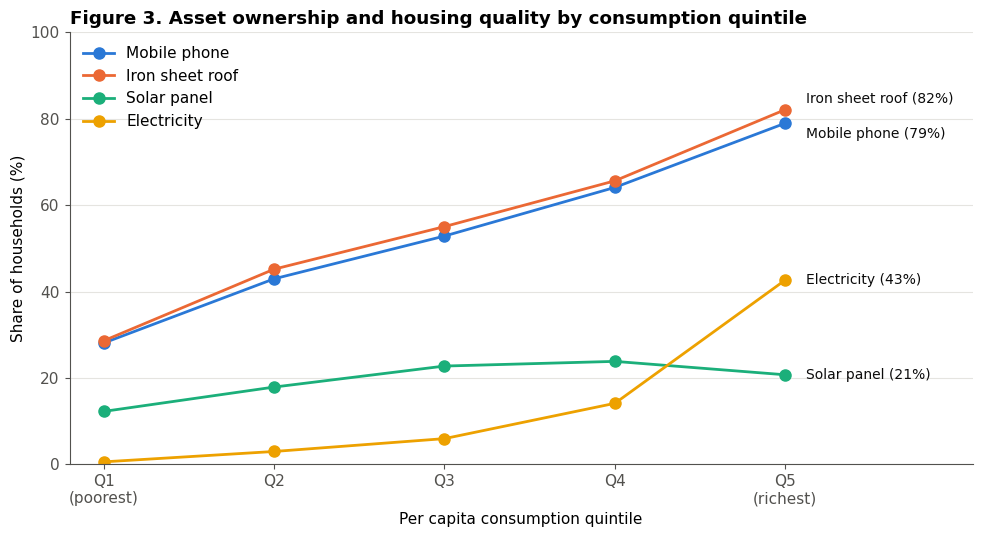

In [10]:
# Visualizations: rebuild an unscaled copy of the merged data (df itself is already scaled and one-hot encoded)
import matplotlib.pyplot as plt

viz = cons.merge(demographics, on='hhid', how='inner').merge(housing, on='hhid', how='inner')\
    .merge(assets, on='hhid', how='inner').merge(education, on='hhid', how='inner').drop_duplicates(subset=['hhid'])
viz['Per Capita'] = viz['Consumption'] / viz['hh_size']
viz['Region'] = viz['region'].map({1: 'North', 2: 'Central', 3: 'Southern'})
viz['Area'] = viz['urban'].map({1: 'Urban', 2: 'Rural'})

# National poverty line is annual real consumption per capita in Kwacha, convert to USD PPP like consumption
poverty_line = pd.read_csv(DATA_DIR / 'ihs5_consumption_aggregate.csv', usecols=['pline'])['pline'].iloc[0] / ppp_factor

BLUE, ORANGE, AQUA, YELLOW, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#0b0b0b', '#52514e'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 11, 'axes.titleweight': 'bold'})

# Figure 1: distribution of per capita consumption against the national poverty line
share_poor = (viz['Per Capita'] < poverty_line).mean() * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
log_bins = np.logspace(np.log10(viz['Per Capita'].min()), np.log10(viz['Per Capita'].max()), 60)
ax.hist(viz['Per Capita'], bins=log_bins, color=BLUE, edgecolor='white', linewidth=0.5)
ax.set_xscale('log')
ax.axvline(poverty_line, color=INK, linestyle='--', linewidth=1)
ax.text(0.98, 0.92, f'Dashed line: national poverty line (${poverty_line:,.0f})\n{share_poor:.0f}% of households fall below it',
        transform=ax.transAxes, ha='right', va='top', color=INK)
ax.set_xlabel('Annual consumption per person (USD PPP, log scale)')
ax.set_ylabel('Number of households')
ax.set_title(f'Figure 1. Distribution of per capita consumption (n = {len(viz):,})', loc='left')
plt.tight_layout()
plt.show()

# Figure 2: median per capita consumption by region, split by urban and rural
by_area = viz.groupby(['Region', 'Area'])['Per Capita'].agg(['median', 'count']).reset_index()
regions = ['North', 'Central', 'Southern']
fig, ax = plt.subplots(figsize=(10, 4.5))
for area, col, offset in [('Rural', ORANGE, -0.18), ('Urban', BLUE, 0.18)]:
    rows = by_area[by_area['Area'] == area].set_index('Region').loc[regions]
    bars = ax.barh(np.arange(3) + offset, rows['median'], height=0.34, color=col, label=area)
    ax.bar_label(bars, labels=[f'{area}: ${m:,.0f}  (n={n:,})' for m, n in zip(rows['median'], rows['count'])], padding=4, color=INK, fontsize=10)
ax.set_yticks(range(3))
ax.set_yticklabels(regions)
ax.invert_yaxis()
ax.set_xlim(0, by_area['median'].max() * 1.45)
ax.set_xlabel('Median annual consumption per person (USD PPP)')
ax.legend(frameon=False, loc='lower right')
ax.set_title('Figure 2. Median per capita consumption by region and area', loc='left')
plt.tight_layout()
plt.show()

# Figure 3: asset ownership and housing quality across per capita consumption quintiles
viz['Quintile'] = pd.qcut(viz['Per Capita'], 5, labels=['Q1\n(poorest)', 'Q2', 'Q3', 'Q4', 'Q5\n(richest)'])
indicators = {'Mobile phone': viz['Mobile phone'] > 0, 'Iron sheet roof': viz['Roof'] == 'IRON SHEETS',
              'Solar panel': viz['Solar panel'] > 0, 'Electricity': viz['Electricity'] == 'YES'}
shares = pd.DataFrame({k: v.groupby(viz['Quintile'], observed=True).mean() * 100 for k, v in indicators.items()})
# Nudge end labels apart where lines finish close together
label_offsets = {'Mobile phone': -2.5, 'Iron sheet roof': 2.5}
fig, ax = plt.subplots(figsize=(10, 5.5))
for c, col in zip(shares.columns, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.plot(range(5), shares[c], marker='o', markersize=8, linewidth=2, color=col, label=c)
    ax.text(4.12, shares[c].iloc[-1] + label_offsets.get(c, 0), f'{c} ({shares[c].iloc[-1]:.0f}%)', color=INK, va='center', fontsize=10)
ax.set_xticks(range(5))
ax.set_xticklabels(shares.index)
ax.set_xlim(-0.2, 5.1)
ax.set_ylim(0, 100)
ax.set_ylabel('Share of households (%)')
ax.set_xlabel('Per capita consumption quintile')
ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
ax.legend(frameon=False, loc='upper left')
ax.set_title('Figure 3. Asset ownership and housing quality by consumption quintile', loc='left')
plt.tight_layout()
plt.show()

## Model Training

In [11]:
def train_consumption_model(random_state=0):
    """Train LASSO model to predict consumption from survey features.

    Returns:
        DataFrame with columns 'y_test' (actual) and 'yhat_test' (predicted),
        both in USD PPP.
    """
    df = pd.read_csv('survey2019.csv')

    outcome = 'Consumption'
    extras = ['hhid']

    # Train/test split, log-transform consumption
    train, test = train_test_split(df, random_state=random_state, test_size=0.25)
    x_train = train.drop([outcome] + extras, axis=1)
    y_train = np.log(train[outcome])
    x_test = test.drop([outcome] + extras, axis=1)
    y_test = np.log(test[outcome])

    # Train LASSO with cross-validated alpha
    model = LassoCV(fit_intercept=True, random_state=random_state, n_jobs=-1)
    model.fit(x_train, y_train)
    yhat_test = model.predict(x_test)

    # Back-transform to USD PPP
    results = pd.DataFrame({
        'y_test': np.exp(y_test),
        'yhat_test': np.exp(yhat_test)
    })

    return results

# Calibrating the PMT and the Relative Value of Prediction

This section takes the cleaned Malawi data (`survey2019.csv`) and repeats the Ethiopia analysis:

1. **Calibrates a proxy means test (PMT).** Runs `train_consumption_model` (LASSO on log consumption, 75/25 split) over 100 random splits.
2. **Evaluates the PMT.** It reports R² on log consumption (averaged over the splits) and a calibration plot.
3. **Replicates the first two case studies** from the replication repo's `poverty-targeting.ipynb` with the `rvp` package: step-function utility and CRRA utility.

Parameters are the same as the Ethiopia notebook so the two countries can be compared: poverty line = 33rd percentile, benefit b = \$100 PPP, CRRA ρ = 3, data collection cost = \$13 PPP per household. Malawi's own national poverty line is higher: 39% of households fall below it (Figure 1).

In [ ]:
%pip install -q git+https://github.com/unai-fa/relative-value-of-prediction.git

## Calibrate the PMT over 100 train/test splits

Each split is saved as `pmt_predictions/seed_XXX.csv` with the two columns `rvp` expects: `ground_truth` (actual consumption, USD PPP) and `predictions` (PMT-predicted consumption, USD PPP). All test sets have the same size, which `rvp` needs to average welfare across splits.

In [11]:
from pathlib import Path
from sklearn.metrics import r2_score

N_SEEDS = 100
POVERTY_SHARE = 0.33
PRED_DIR = Path('pmt_predictions')
PRED_DIR.mkdir(exist_ok=True)

def calibrate_pmt(random_state):
    """Run the LASSO PMT for one train/test split, in the column format rvp expects."""
    res = train_consumption_model(random_state=random_state)
    return pd.DataFrame({'ground_truth': res['y_test'].values, 'predictions': res['yhat_test'].values})

r2_scores = []
for seed in range(N_SEEDS):
    out = calibrate_pmt(seed)
    out.to_csv(PRED_DIR / f'seed_{seed:03d}.csv', index=False)
    r2_scores.append(r2_score(np.log(out['ground_truth']), np.log(out['predictions'])))

r2_scores = pd.Series(r2_scores)
print(f'Saved {N_SEEDS} prediction files to {PRED_DIR}/')
print(f'R2 (log): {r2_scores.mean():.3f} (std {r2_scores.std():.3f} over {N_SEEDS} splits)')

Saved 100 prediction files to pmt_predictions/
R2 (log): 0.648 (std 0.009 over 100 splits)


### PMT calibration and targeting curve

Left: predicted vs. actual consumption for one split. Middle: calibration, comparing mean actual and mean predicted log consumption within deciles of the prediction (points on the 45° line mean the PMT is well calibrated). Right: the share of truly poor households reached as program capacity grows, averaged over the 100 splits, against perfect targeting and random allocation.

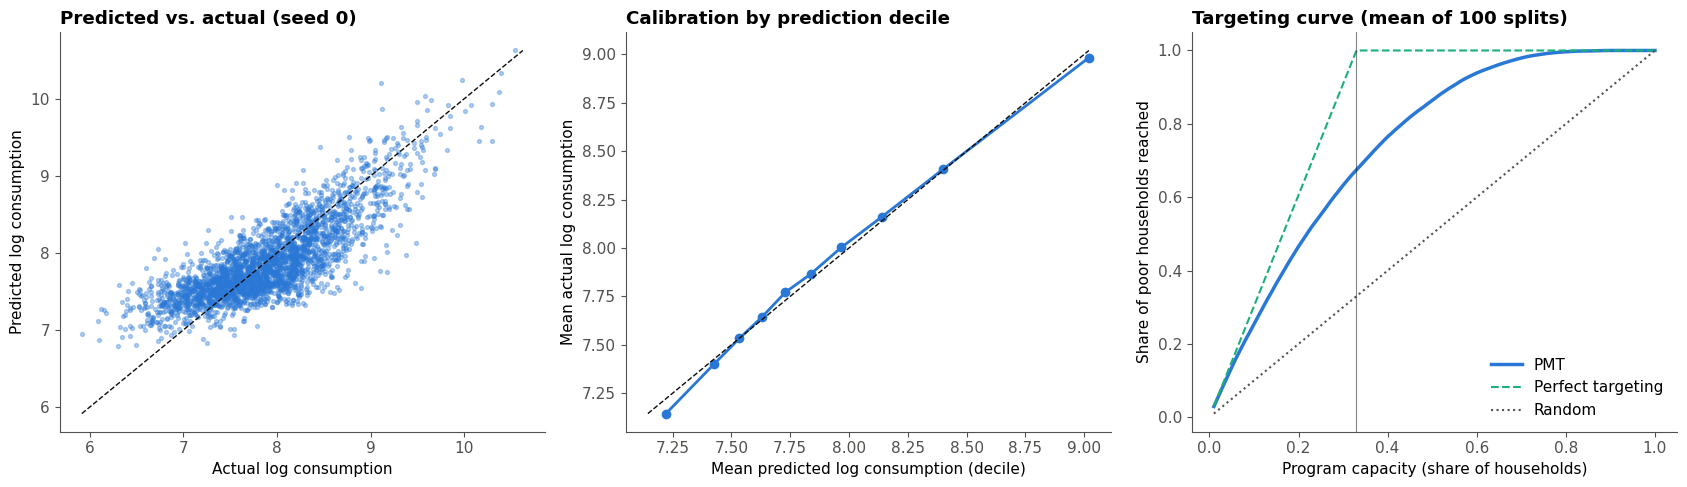

In [14]:
seed_files = sorted(PRED_DIR.glob('seed_*.csv'))
pmt_runs = [pd.read_csv(f) for f in seed_files]
ex = pmt_runs[0]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
ax.scatter(np.log(ex['ground_truth']), np.log(ex['predictions']), s=8, alpha=0.35, color=BLUE)
lims = [np.log(ex[['ground_truth', 'predictions']].values).min(), np.log(ex[['ground_truth', 'predictions']].values).max()]
ax.plot(lims, lims, color=INK, linestyle='--', linewidth=1)
ax.set_xlabel('Actual log consumption')
ax.set_ylabel('Predicted log consumption')
ax.set_title('Predicted vs. actual (seed 0)', loc='left')

ax = axes[1]
calib = []
for run in pmt_runs:
    d = np.log(run).assign(decile=lambda t: pd.qcut(t['predictions'], 10, labels=False))
    calib.append(d.groupby('decile')[['predictions', 'ground_truth']].mean())
calib = pd.concat(calib).groupby(level=0).mean()
ax.plot(calib['predictions'], calib['ground_truth'], marker='o', color=BLUE, linewidth=2)
lo, hi = calib.values.min(), calib.values.max()
ax.plot([lo, hi], [lo, hi], color=INK, linestyle='--', linewidth=1)
ax.set_xlabel('Mean predicted log consumption (decile)')
ax.set_ylabel('Mean actual log consumption')
ax.set_title('Calibration by prediction decile', loc='left')

ax = axes[2]
caps = np.linspace(0.01, 1.0, 100)
curves = []
for run in pmt_runs:
    n = len(run)
    poor = (run['ground_truth'].rank(method='first') <= round(POVERTY_SHARE * n)).values
    order = np.argsort(run['predictions'].values)
    curves.append([poor[order[:int(round(c * n))]].sum() / poor.sum() for c in caps])
ax.plot(caps, np.mean(curves, axis=0), color=BLUE, linewidth=2.5, label='PMT')
ax.plot(caps, np.minimum(caps / POVERTY_SHARE, 1), color=AQUA, linestyle='--', label='Perfect targeting')
ax.plot(caps, caps, color=MUTED, linestyle=':', label='Random')
ax.axvline(POVERTY_SHARE, color=INK, linewidth=0.8, alpha=0.5)
ax.set_xlabel(r'Program capacity (share of households)')
ax.set_ylabel('Share of poor households reached')
ax.set_title('Targeting curve (mean of 100 splits)', loc='left')
ax.legend(frameon=False, loc='lower right')

plt.tight_layout()
plt.show()

## Allocation problem

Same setup as the Ethiopia notebook and the replication repo. The planner ranks households by predicted consumption (poorest first). `utility` is CRRA welfare gain with ρ = 3; `utility_step` counts how many households below the 33% poverty line are reached. `AllocationData` averages every welfare number over the first 25 splits (set `N_RVP_SPLITS = 100` to use all of them; it is about 4x slower). Malawi's test sets are about 2.4x larger than Ethiopia's, so each surface also takes longer.

In [15]:
from rvp import (AllocationData, AllocationProblem, BenefitDimension, CapacityDimension,
                 CostSurface, DataLabelingDimension, DesignSpace, plot_welfare_surface)
from rvp.constraints import CoverageConstraint
from rvp.policies import RankingPolicy
from rvp.utilities import CRRAUtility, PartitionedUtility
from rvp.comparison import optimize_budget_frontier
from rvp.design.dimensions.data_labeling import DataLabelingDimension
from rvp.design.space import DesignSpace as _DesignSpace

# Speed-ups (same results): every welfare_at() call used to copy all splits and rebuild AllocationData,
# and every Q1/Q2/Q3 plot recomputed an identical 900-point surface. Cache both.
_orig_label_at = DataLabelingDimension.at
def _cached_label_at(self, problem, theta):
    cache = self.__dict__.setdefault('_data_cache', {})
    key = round(float(theta), 12)
    if key not in cache:
        cache[key] = _orig_label_at(self, problem, theta).data
    return AllocationProblem(data=cache[key], utility=problem.utility,
                             constraint=problem.constraint, policy=problem.policy)
DataLabelingDimension.at = _cached_label_at

_orig_surface = getattr(_DesignSpace, '_orig_welfare_surface', _DesignSpace.welfare_surface)
_DesignSpace._orig_welfare_surface = _orig_surface
_surface_cache = {}
def _cached_surface(self, dim_x, dim_y, fixed=None, n=50, metric='mean_utility', subgroup_mask=None):
    if subgroup_mask is not None:
        return _orig_surface(self, dim_x, dim_y, fixed, n, metric, subgroup_mask)
    key = (self, dim_x, dim_y, tuple(sorted((fixed or {}).items(), key=lambda kv: id(kv[0]))), n, metric)
    if key not in _surface_cache:
        _surface_cache[key] = _orig_surface(self, dim_x, dim_y, fixed, n, metric)
    x, y, W = _surface_cache[key]
    return x.copy(), y.copy(), W.copy()
_DesignSpace.welfare_surface = _cached_surface

# The repo uses LaTeX text rendering; keep it off so the notebook runs without a LaTeX install
plt.rcParams.update({'text.usetex': False, 'font.size': 14, 'axes.labelsize': 16, 'axes.titlesize': 16,
                     'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 12})

# Welfare surfaces re-rank every split at every grid point, which is slow with 100 splits
# (~3.5 min per surface). Averaging over 25 splits gives near-identical surfaces ~4x faster.
N_RVP_SPLITS = 25
data = AllocationData(df=pmt_runs[:N_RVP_SPLITS])

BASE_BENEFIT = 100
RHO = 3.0
COST_PER_LABEL = 13

policy = RankingPolicy(ascending=True)
utility = CRRAUtility(rho=RHO, b=BASE_BENEFIT)
utility_step = PartitionedUtility(thresholds=[POVERTY_SHARE], values=[1, 0], threshold_type='percentile')
constraint = CoverageConstraint(max_coverage=1.0, population_size=data.n)

base_problem = AllocationProblem(data=data, utility=utility, constraint=constraint, policy=policy)
base_problem_step = AllocationProblem(data=data, utility=utility_step, constraint=constraint, policy=policy)

print(f'{data.n_datasets} splits x {data.n} test households each')
base_problem.evaluate()

25 splits x 2859 test households each


{'total_utility': 6.085824505977692e-05,
 'mean_utility': 2.1286549513737992e-08,
 'utility_ratio': 1.0,
 'n_allocated': 2859.0,
 'actions': None}

## Design space

Three levers: capacity α (share of households that receive a transfer), benefit b (transfer size), and label fraction (share of households with PMT data collected; the rest get the population-mean score and are ranked at random).

In [16]:
capacity_dim = CapacityDimension(bounds=(0.01, 1.0), name=r'Capacity ($\alpha$)')
benefit_dim = BenefitDimension(bounds=(1, 1000), name=r'Benefit ($b$)')
labeling_dim = DataLabelingDimension(base_problem=base_problem, bounds=(0.0, 1.0), seed=42,
                                     name='Label Fraction', unlabeled_strategy='population_mean')

space = DesignSpace(base_problem=base_problem, dimensions=[capacity_dim, benefit_dim, labeling_dim])
space_step = DesignSpace(base_problem=base_problem_step, dimensions=[capacity_dim, labeling_dim])

welfare_norm = space.welfare_at({capacity_dim: 1.0, benefit_dim: 100, labeling_dim: 1.0}, metric='mean_utility')

cost_surface = CostSurface(lambda config: data.n * (
    float(config[capacity_dim]) * float(BASE_BENEFIT) + float(config[labeling_dim]) * COST_PER_LABEL))

STATUS_QUO = {capacity_dim: 0.05, labeling_dim: 0.20}
space

DesignSpace(dimensions=['Capacity ($\\alpha$)', 'Benefit ($b$)', 'Label Fraction'])

### Relative value of prediction at the status quo

A numeric companion to Q2: the marginal welfare per dollar from a small increase in capacity vs. a small increase in data collection, at 5% capacity and 20% coverage. A ratio above 1 means the next dollar does more good spent on prediction (data) than on capacity.

In [17]:
def marginal_value_per_dollar(sp, sq, fixed=None, h=0.01):
    fixed = fixed or {}
    base = {**sq, **fixed}
    w0 = sp.welfare_at(base, metric='mean_utility')
    out = {}
    for dim, unit_cost in [(capacity_dim, BASE_BENEFIT), (labeling_dim, COST_PER_LABEL)]:
        w1 = sp.welfare_at({**base, dim: base[dim] + h}, metric='mean_utility')
        out[dim.name] = (w1 - w0) / (h * unit_cost)
    out['Ratio (data / capacity)'] = out['Label Fraction'] / out[capacity_dim.name]
    return out

rvp_table = pd.DataFrame({
    'Step utility (CS1)': marginal_value_per_dollar(space_step, STATUS_QUO),
    'CRRA utility (CS2)': marginal_value_per_dollar(space, STATUS_QUO, fixed={benefit_dim: BASE_BENEFIT}),
}).T
rvp_table.columns = ['dW/$ capacity', 'dW/$ data', 'Ratio (data / capacity)']
rvp_table

,dW/$ capacity,dW/$ data,Ratio (data / capacity)
Step utility (CS1),4.896817e-03,3.121048e-03,0.637363
CRRA utility (CS2),2.479168e-10,6.391848e-10,2.578223


# Case Study 1: Step-function utility
Welfare = share of households below the poverty line (33%) who are reached.

## (Q1) Local rate of improvement

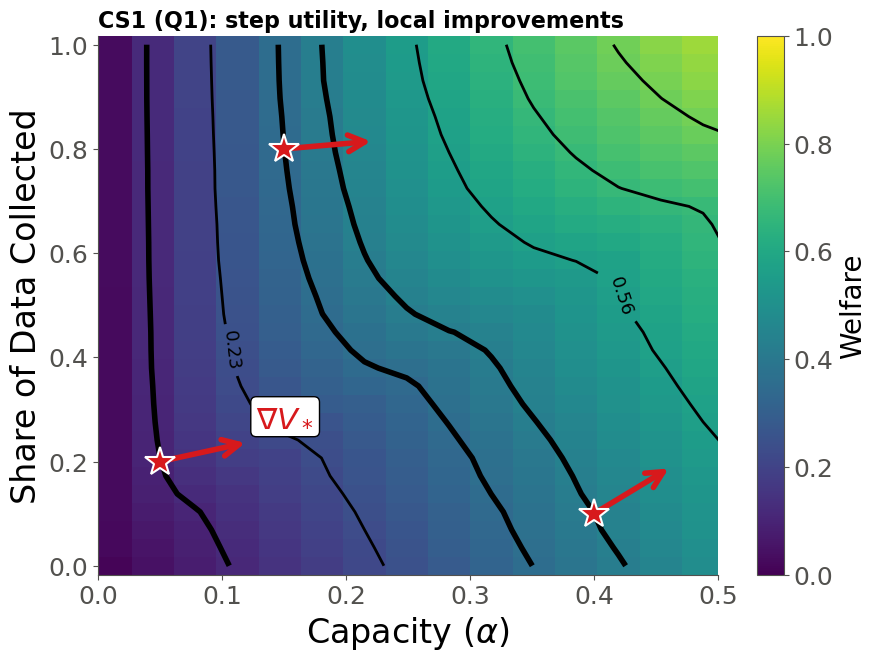

In [18]:
fig, ax = plot_welfare_surface(
    space_step, dim_x=capacity_dim, dim_y=labeling_dim, welfare_metric='mean_utility', normalize='max',
    xlim=(0.0, 0.5), n=30,
    status_quo=[{capacity_dim: 0.05, labeling_dim: 0.2}, {capacity_dim: 0.4, labeling_dim: 0.1},
                {capacity_dim: 0.15, labeling_dim: 0.8}],
    cmap='viridis', n_contours=8, cbar_label='Welfare')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS1 (Q1): step utility, local improvements', loc='left')
plt.show()

## (Q2) Inspecting optimality
The cost overlay shows the iso-cost line through the status quo (\$13 per label, \$100 per transfer).

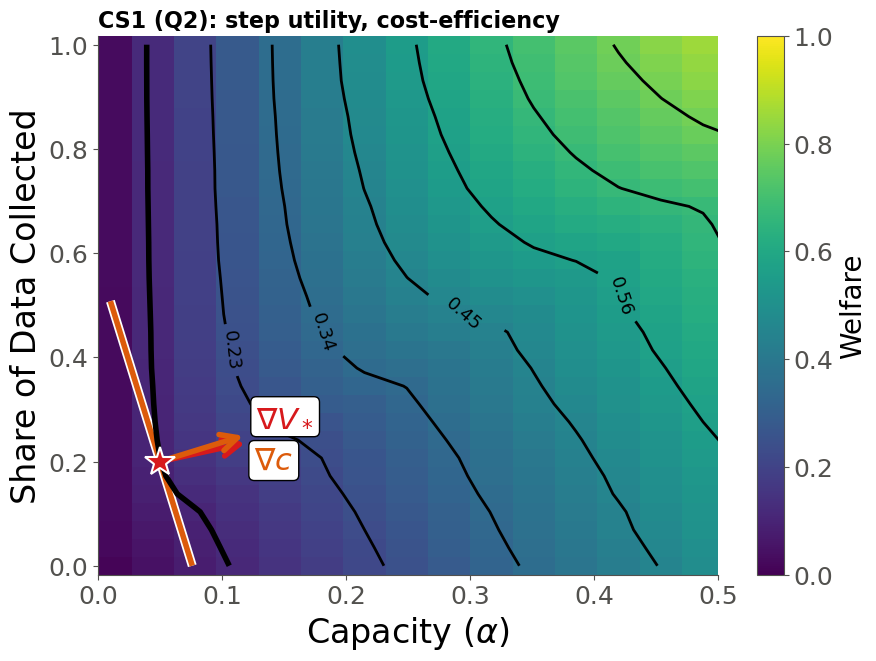

In [19]:
fig, ax = plot_welfare_surface(
    space_step, dim_x=capacity_dim, dim_y=labeling_dim, welfare_metric='mean_utility', normalize='max',
    xlim=(0.0, 0.5), n=30, status_quo=STATUS_QUO, cmap='viridis', cost_surface=cost_surface,
    n_contours=8, cbar_label='Welfare')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS1 (Q2): step utility, cost-efficiency', loc='left')
plt.show()

## (Q3) Choosing optimal parameters (expansion path)

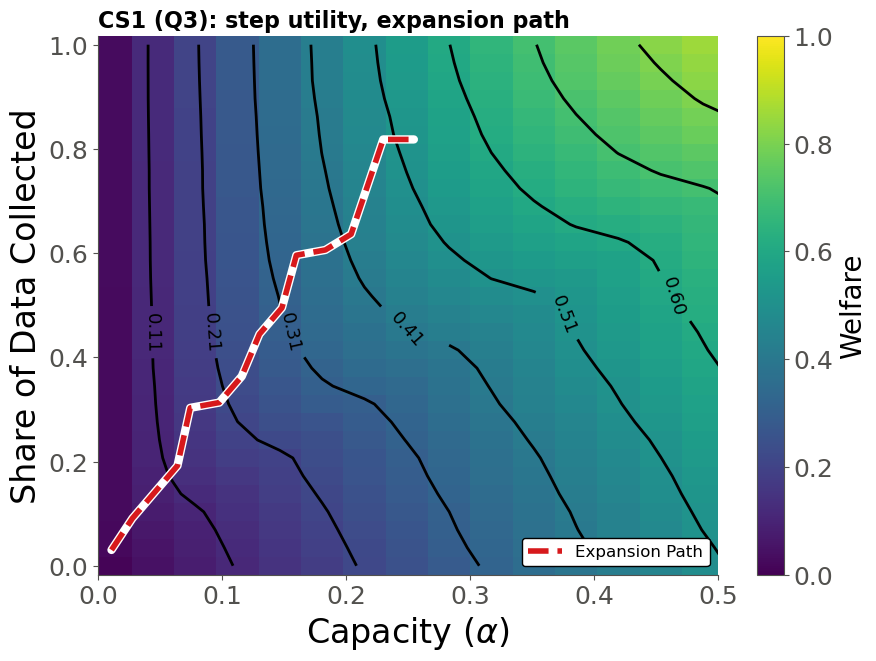

,budget,optimal_welfare,optimal_cost,unspent_budget,optimal_Capacity ($\alpha$)_theta,optimal_Label Fraction_theta
0,1000.000000,0.006744,1000.000000,4.547474e-13,0.010858,0.030303
1,8071.428571,0.018272,8071.428571,-9.094947e-13,0.027713,0.090909
2,15142.857143,0.029871,15142.857143,-3.637979e-12,0.045882,0.141414
3,22214.285714,0.041623,22214.285714,-3.637979e-12,0.064050,0.191919
4,29285.714286,0.053641,29285.714286,0.000000e+00,0.074339,0.303030
5,36357.142857,0.065813,36357.142857,0.000000e+00,0.097760,0.313131
6,43428.571429,0.077859,43428.571429,7.275958e-12,0.115929,0.363636
7,50500.000000,0.090269,50500.000000,-7.275958e-12,0.130157,0.444444
8,57571.428571,0.102218,57571.428571,1.455192e-11,0.148326,0.494949
9,64642.857143,0.114236,64642.857143,0.000000e+00,0.159928,0.595960


In [20]:
BUDGET_MAX_ADDITIONAL = 100_000
N_BUDGET_POINTS = 15
OPT_GRID_N = (100, 100)
PATH_START = {capacity_dim: 0.01, labeling_dim: 0.01}

budget_results_step, budget_candidates_step = optimize_budget_frontier(
    space=space_step, cost_surface=cost_surface, solve_dim=capacity_dim,
    budget_range=(1000, BUDGET_MAX_ADDITIONAL), n_budget_points=N_BUDGET_POINTS,
    status_quo=PATH_START, n=OPT_GRID_N, welfare_metric='mean_utility', return_candidates=True)

fig, ax = plot_welfare_surface(
    space_step, dim_x=capacity_dim, dim_y=labeling_dim, welfare_metric='mean_utility', n=30,
    normalize='max', cbar_label='Welfare', xlim=(0, 0.5),
    path_results=budget_results_step, path_label='Expansion Path')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS1 (Q3): step utility, expansion path', loc='left')
plt.show()
budget_results_step.head(N_BUDGET_POINTS)

# Case Study 2: CRRA utility
Welfare = CRRA utility gain (ρ = 3) from a \$100 PPP transfer, which weights gains to the poorest households most.

## (Q1) Local rate of improvement

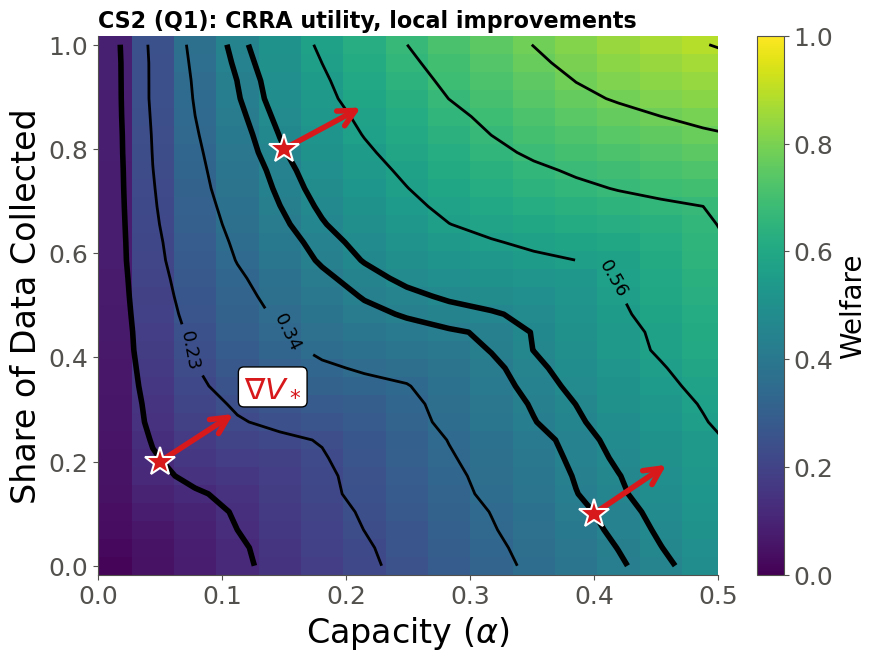

In [21]:
fig, ax = plot_welfare_surface(
    space, dim_x=capacity_dim, dim_y=labeling_dim, fixed={benefit_dim: BASE_BENEFIT},
    welfare_metric='mean_utility', normalize_by=welfare_norm, n=30, xlim=(0.0, 0.5),
    status_quo=[{capacity_dim: 0.05, labeling_dim: 0.2}, {capacity_dim: 0.4, labeling_dim: 0.1},
                {capacity_dim: 0.15, labeling_dim: 0.8}],
    cmap='viridis', n_contours=8, cbar_label='Welfare')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS2 (Q1): CRRA utility, local improvements', loc='left')
plt.show()

## (Q2) Inspecting optimality

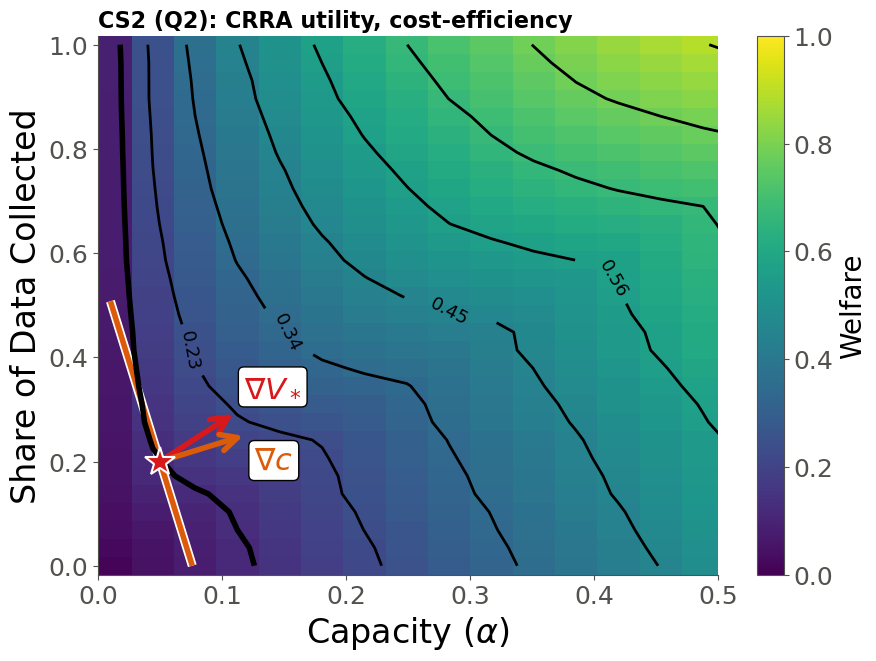

In [22]:
fig, ax = plot_welfare_surface(
    space, dim_x=capacity_dim, dim_y=labeling_dim, fixed={benefit_dim: BASE_BENEFIT},
    welfare_metric='mean_utility', normalize_by=welfare_norm, xlim=(0.0, 0.5), n=30,
    status_quo=STATUS_QUO, cmap='viridis', cost_surface=cost_surface, n_contours=8, cbar_label='Welfare')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS2 (Q2): CRRA utility, cost-efficiency', loc='left')
plt.show()

## (Q3) Choosing optimal parameters (expansion path)

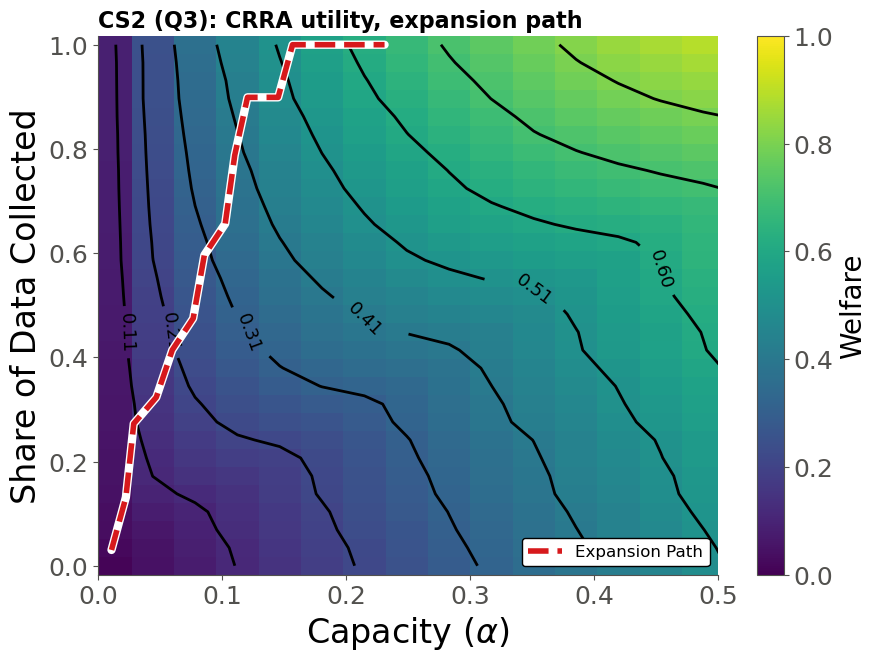

,budget,optimal_welfare,optimal_cost,unspent_budget,optimal_Capacity ($\alpha$)_theta,optimal_Label Fraction_theta
0,1000.000000,4.603545e-10,1000.000000,4.547474e-13,0.010858,0.030303
1,8071.428571,1.431308e-09,8071.428571,9.094947e-13,0.022461,0.131313
2,15142.857143,2.408959e-09,15142.857143,-3.637979e-12,0.028811,0.272727
3,22214.285714,3.393587e-09,22214.285714,-3.637979e-12,0.046979,0.323232
4,29285.714286,4.436141e-09,29285.714286,0.000000e+00,0.059895,0.414141
5,36357.142857,5.395546e-09,36357.142857,0.000000e+00,0.076750,0.474747
6,43428.571429,6.431251e-09,43428.571429,7.275958e-12,0.085727,0.595960
7,50500.000000,7.408050e-09,50500.000000,0.000000e+00,0.102582,0.656566
8,57571.428571,8.370665e-09,57571.428571,1.455192e-11,0.110245,0.787879
9,64642.857143,9.359261e-09,64642.857143,1.455192e-11,0.120534,0.898990


In [23]:
budget_results_crra, budget_candidates_crra = optimize_budget_frontier(
    space=space, cost_surface=cost_surface, solve_dim=capacity_dim,
    budget_range=(1000, BUDGET_MAX_ADDITIONAL), n_budget_points=N_BUDGET_POINTS,
    status_quo={**PATH_START, benefit_dim: BASE_BENEFIT}, fixed={benefit_dim: BASE_BENEFIT},
    n=100, welfare_metric='mean_utility', return_candidates=True)

fig, ax = plot_welfare_surface(
    space, dim_x=capacity_dim, dim_y=labeling_dim, fixed={benefit_dim: BASE_BENEFIT},
    welfare_metric='mean_utility', n=30, normalize='max', cbar_label='Welfare', xlim=(0, 0.5),
    path_results=budget_results_crra, path_label='Expansion Path')
ax.set_ylabel('Share of Data Collected')
ax.set_title('CS2 (Q3): CRRA utility, expansion path', loc='left')
plt.show()
budget_results_crra.head(N_BUDGET_POINTS)